<a href="https://colab.research.google.com/github/papoochu/student-ai-learning-analysis/blob/main/notebooks/k_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Step 1: Load StudyChat using the same source as the original notebook
import pandas as pd
from huggingface_hub import notebook_login

notebook_login()  # Sign in with a Hugging Face token if prompted

df = pd.read_json(
    "hf://datasets/wmcnicho/StudyChat/data.jsonl",
    lines=True
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Unique students:", df["userId"].nunique())

Dataset shape: (16851, 13)
Columns: ['prompt', 'response', 'topic', 'messages', 'timestamp', 'chatId', 'userId', 'interactionCount', 'chatTitle', 'chatStartTime', 'chatTotalInteractionCount', 'llm_label', 'semester']
Unique students: 203


In [2]:

# Step 2: Clean and segment StudyChat

import pandas as pd

# Keep the original data unchanged
corpus = df.copy()

# Remove missing and blank prompts
corpus = corpus.dropna(subset=["prompt"]).copy()
corpus["prompt"] = corpus["prompt"].astype(str).str.strip()
corpus = corpus[corpus["prompt"] != ""].copy()

# Count words in each prompt
corpus["word_count"] = (
    corpus["prompt"].str.split().str.len()
)

# Remove prompts longer than 1,000 words
modeling_corpus = corpus[
    corpus["word_count"] <= 1000
].copy()

# Reset indices for consistent document alignment
modeling_corpus = modeling_corpus.reset_index(drop=True)

# Each prompt is one document
docs = modeling_corpus["prompt"].tolist()

print("Original interactions:", len(df))
print("Nonblank prompts:", len(corpus))
print("Modeling prompts:", len(modeling_corpus))
print("Unique students:", modeling_corpus["userId"].nunique())
print("Duplicate prompts retained:", modeling_corpus["prompt"].duplicated().sum())


Original interactions: 16851
Nonblank prompts: 16850
Modeling prompts: 16597
Unique students: 203
Duplicate prompts retained: 1234


In [3]:

# Step 3: Preprocess StudyChat prompts for K-means

import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words_v2 = set(ENGLISH_STOP_WORDS)

def preprocess_text_v2(text):
    # Extract words and preserve programming identifiers
    tokens = re.findall(
        r"\b[a-z_][a-z0-9_]*\b",
        text.lower()
    )

    # Remove stop words and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words_v2 and len(word) > 2
    ]

    return " ".join(tokens)

# Apply preprocessing
modeling_corpus["processed_text_v2"] = (
    modeling_corpus["prompt"].apply(preprocess_text_v2)
)

# Check the results
print("Total processed prompts:", len(modeling_corpus))
print(
    "Empty after preprocessing:",
    (modeling_corpus["processed_text_v2"] == "").sum()
)

print("\nOriginal prompt:")
print(modeling_corpus["prompt"].iloc[0][:400])

print("\nProcessed prompt:")
print(modeling_corpus["processed_text_v2"].iloc[0][:400])


Total processed prompts: 16597
Empty after preprocessing: 150

Original prompt:
cross validation tests it on multiple sets, so does it randomly select data on my dataset? concise

Processed prompt:
cross validation tests multiple sets does randomly select data dataset concise


In [4]:

# Step 4: Create TF-IDF vectors for K-means

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vect = TfidfVectorizer(
    max_df=0.8,
    min_df=5,
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf = tfidf_vect.fit_transform(
    modeling_corpus["processed_text_v2"].fillna("")
)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf_vect.vocabulary_))
print("Nonzero TF-IDF values:", X_tfidf.nnz)

# Verify that the row count matches our documents
assert X_tfidf.shape[0] == len(modeling_corpus)

print("TF-IDF matrix ready!")


TF-IDF matrix shape: (16597, 5000)
Vocabulary size: 5000
Nonzero TF-IDF values: 544703
TF-IDF matrix ready!


In [5]:

# Step 5: Train our selected K-means model

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

kmeans_31 = KMeans(
    n_clusters=31,
    random_state=42,
    n_init=10
)

# Train the model and assign each prompt to a cluster
labels_31 = kmeans_31.fit_predict(X_tfidf)

# Save cluster assignments
modeling_corpus["cluster_31"] = labels_31

# Count prompts in each cluster
cluster_counts = (
    modeling_corpus["cluster_31"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Total clusters:", len(cluster_counts))
print("Total assigned prompts:", cluster_counts.sum())

print("\nFive largest clusters:")
display(cluster_counts.head(5).to_frame("Prompts"))

print("\nFive smallest clusters:")
display(cluster_counts.tail(5).to_frame("Prompts"))


Total clusters: 31
Total assigned prompts: 16597

Five largest clusters:


,Prompts
cluster_31,
27,7046
1,682
23,642
12,591
29,577



Five smallest clusters:


,Prompts
cluster_31,
22,140
11,118
18,117
21,114
28,49


In [6]:

# Step 6: Identify K-means cluster topics

import pandas as pd
import numpy as np

feature_names = tfidf_vect.get_feature_names_out()

cluster_summary = []

for cluster_id in range(31):

    # Find the eight highest-weighted terms
    center = kmeans_31.cluster_centers_[cluster_id]

    top_indices = np.argsort(center)[-8:][::-1]

    top_words = [
        feature_names[i] for i in top_indices
    ]

    # Count documents assigned to this cluster
    count = int(np.sum(labels_31 == cluster_id))

    cluster_summary.append({
        "Cluster": cluster_id,
        "Prompts": count,
        "Share (%)": 100 * count / len(labels_31),
        "Top Keywords": ", ".join(top_words)
    })

cluster_summary_df = pd.DataFrame(cluster_summary)

display(
    cluster_summary_df
    .sort_values("Prompts", ascending=False)
    .round(2)
)


,Cluster,Prompts,Share (%),Top Keywords
27,27,7046,42.45,"make, explain, model, dataset, write, using, s..."
1,1,682,4.11,"data, table, markdown, load, markdown table, p..."
23,23,642,3.87,"regression, neural, cross, validation, cross v..."
12,12,591,3.56,"tensor, torch, shape, ones, tensor shape, torc..."
29,29,577,3.48,"hidden, stride, hidden_size, self, torch, batc..."
4,4,528,3.18,"node, children, char, self, node children, pre..."
16,16,495,2.98,"does, mean, does mean, work, score, does score..."
9,9,428,2.58,"rows, duplicate, duplicate rows, missing, drop..."
14,14,395,2.38,"code, write, write code, intuition, intuition ..."
25,25,391,2.36,"column, dataframe, csv, export, json, row, pan..."


In [7]:

# Step 7: Calculate silhouette scores for individual clusters

import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_samples

# Reproducible sample of 2,000 prompts
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_tfidf.shape[0],
    size=2000,
    replace=False
)

X_sample = X_tfidf[sample_indices]
sampled_labels = np.asarray(labels_31)[sample_indices]

# Calculate silhouette score for each sampled prompt
silhouette_values = silhouette_samples(
    X_sample,
    sampled_labels,
    metric="euclidean"
)

# Summarize scores for each cluster
cluster_silhouette_results = []

for cluster_id in sorted(np.unique(sampled_labels)):

    mask = sampled_labels == cluster_id

    cluster_silhouette_results.append({
        "Cluster": int(cluster_id),
        "Sampled Prompts": int(mask.sum()),
        "Average Silhouette": float(
            silhouette_values[mask].mean()
        ),
        "Top Keywords": cluster_summary_df.loc[
            cluster_summary_df["Cluster"] == cluster_id,
            "Top Keywords"
        ].iloc[0]
    })

cluster_quality_df = pd.DataFrame(
    cluster_silhouette_results
)

print("TOP 5 CLUSTERS:")
display(
    cluster_quality_df.nlargest(
        5, "Average Silhouette"
    ).round(4)
)

print("\nBOTTOM 5 CLUSTERS:")
display(
    cluster_quality_df.nsmallest(
        5, "Average Silhouette"
    ).round(4)
)

print(
    "\nOverall sampled silhouette:",
    round(float(silhouette_values.mean()), 4)
)


TOP 5 CLUSTERS:


,Cluster,Sampled Prompts,Average Silhouette,Top Keywords
28,28,6,0.7355,"conversions, conversion hallucinations, conver..."
18,18,16,0.5068,"start_text, temperature, logits, generate_text..."
26,26,24,0.4536,"query, target, sql, count, select target, grou..."
5,5,32,0.3796,"blood, cell, red blood, red, pus, blood cell, ..."
22,22,20,0.3679,"split features, features, split, test, feature..."



BOTTOM 5 CLUSTERS:


,Cluster,Sampled Prompts,Average Silhouette,Top Keywords
27,27,856,-0.0040,"make, explain, model, dataset, write, using, s..."
23,23,70,0.0019,"regression, neural, cross, validation, cross v..."
1,1,73,0.0069,"data, table, markdown, load, markdown table, p..."
14,14,50,0.0225,"code, write, write code, intuition, intuition ..."
25,25,47,0.0225,"column, dataframe, csv, export, json, row, pan..."



Overall sampled silhouette: 0.0685


In [8]:

# Step 8: Inspect example prompts from selected clusters

import pandas as pd

selected_clusters = {
    28: "High silhouette: LLM conversions",
    26: "High silhouette: SQL queries",
    27: "Low silhouette: General requests",
    23: "Low silhouette: Regression",
    1: "Low silhouette: Data tables"
}

examples = []

for cluster_id, description in selected_clusters.items():

    cluster_docs = modeling_corpus[
        modeling_corpus["cluster_31"] == cluster_id
    ]

    # Random examples to avoid cherry-picking
    sampled = cluster_docs.sample(
        n=min(4, len(cluster_docs)),
        random_state=42
    )

    for _, row in sampled.iterrows():
        examples.append({
            "Cluster": cluster_id,
            "Description": description,
            "Prompt": row["prompt"][:350]
        })

examples_df = pd.DataFrame(examples)

pd.set_option("display.max_colwidth", 350)

for cluster_id, description in selected_clusters.items():
    print(f"\nCLUSTER {cluster_id}: {description}")
    display(
        examples_df[
            examples_df["Cluster"] == cluster_id
        ][["Prompt"]]
    )



CLUSTER 28: High silhouette: LLM conversions


,Prompt
0,"while language models can perform data conversions they also can * hallucinate * during this process, particularly for bigger datasets. Reflect on this below, how could you mitigate data conversion hallucinations from LLM conversions?"
1,"Part 4: Data conversions with Large Language Models\n\nOne powerful use case of ChatGPT (and other generative language models) is cleaning and transforming data. In some cases, these models can directly manipulate loosely structured data that you provide to them into a standard format. In the other cases, you can often prompt the model to creat..."
2,"** Caution: ** while language models can perform data conversions they also can * hallucinate * during this process, particularly for bigger datasets. Reflect on this below, how could you mitigate data conversion hallucinations from LLM conversions?"
3,"while language models can perform data conversions they also can * hallucinate * during this process, particularly for bigger datasets. Reflect on this below, how could you mitigate data conversion hallucinations from LLM conversions?"



CLUSTER 26: High silhouette: SQL queries


,Prompt
4,"convert this to a pandas query: \n\n**SQL Query**\n```sql\nSELECT Target, COUNT(*) AS count\nFROM your_table_name\nGROUP BY Target;\n```"
5,"Convert the following SQL query into a Pandas query: SELECT Target, COUNT(*) AS count\nFROM your_table_name\nGROUP BY Target;"
6,"SELECT Target, COUNT(*) AS count\nFROM your_table_name\nGROUP BY Target;"
7,"convert this SQL query to a pandas query:\n\n**SQL Query**\n```sql\nSELECT Target, COUNT(*) AS count\nFROM your_table_name\nGROUP BY Target;\n```"



CLUSTER 27: Low silhouette: General requests


,Prompt
8,can you explain this to me sorted_dict = {i: myDict[i] for i in myKeys}
9,delete every conversation so far
10,RuntimeError: mat1 and mat2 shapes cannot be multiplied (260x5 and 26x26)
11,dot product between tensors



CLUSTER 23: Low silhouette: Regression


,Prompt
12,can you write the equation given this information? also what can we infer based on this Cross-validation R² scores for polynomial regression: [1. 1. 1. 1. 1.]\nMean R² score for polynomial regression: 1.0\nStandard deviation of R² scores for polynomial regression: 0.0\nCoefficients: [ 0.00000000e+00 1.20000000e+01 -1.27195512e-07 1.26494371e-...
13,"how long is this code supposed to take to run?:\n\nX = ckd_dataset.drop('Target_ckd', axis=1) # Adjust 'class' if your target column is named differently\ny = ckd_dataset['Target_ckd'] \n\nmodels = {\n ""Logistic Regression"": LogisticRegression(),\n ""Support Vector Machine"": SVC(),\n ""k-Nearest Neighbors"": KNeighborsClassifier(),\n ..."
14,help me write a few sentences explainging each of these - Cross-Validation Accuracy Scores:\n Logistic Regression Support Vector Machines k-Nearest Neighbors \\n0 0.870968 0.903226 0.903226 \n1 0.838710 1.000000 0.967742 \n2 0.870968 ...
15,"Part 2: Chronic Kidney Disease Classification\nOverview\nNow that you've tackled regression, let's move on to classification by modeling and analyzing the Chronic Kidney Disease (CKD) dataset that we cleaned in the previous assignment.\n\nIn this part of the assignment will be more open-ended. Unlike Part 1, you will explore different classific..."



CLUSTER 1: Low silhouette: Data tables


,Prompt
16,"We will now load the dataset, preprocess it and create instances of the dataset.\n\n# Define the column names for the dataset\ncolumn_names = [""SepalLength"", ""SepalWidth"", ""PetalLength"", ""PetalWidth"", ""Species""]\n\n# Load the data from the CSV file (above cells) into a Pandas DataFrame\ndata = pd.read_csv(csv_path, names=column_names, header=0)..."
17,how do I type a subscript in markdown
18,assignment guidelines: \n\nIncrease familiarity with Pandas and SciKit Learn libraries for data cleaning\nLearn how to work with messy datasets\nLearn how to combine different datasets\nUnderstand the importance of data preprocessing for improving model performance\nGain experience in encoding categorical features and normalizing numerical feat...
19,"# Load the dataset (load remotely or locally)\niris_data = pd.read_csv('iris.csv')\n\n# Output the first 15 rows of the data\nprint(""First 15 rows of the dataset:"")\nprint(iris_data.head(15))\n# Display a summary of the table information (number of datapoints, etc.)\nprint(""Summary:"")\niris_data.info()"


In [9]:

# Step 9: Investigate repeated prompts in selected clusters

import pandas as pd

selected_cluster_ids = [28, 18, 26, 5, 22, 27, 23, 1]

duplicate_results = []

for cluster_id in selected_cluster_ids:

    cluster_docs = modeling_corpus[
        modeling_corpus["cluster_31"] == cluster_id
    ].copy()

    # Normalize whitespace for a fairer exact-text comparison
    normalized = (
        cluster_docs["prompt"]
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    total = len(cluster_docs)
    unique = normalized.nunique()

    duplicate_results.append({
        "Cluster": cluster_id,
        "Total Prompts": total,
        "Unique Prompts": unique,
        "Duplicate Rate (%)": 100 * (total - unique) / total,
        "Unique Students": cluster_docs["userId"].nunique()
    })

duplicate_df = pd.DataFrame(duplicate_results)

display(
    duplicate_df.sort_values(
        "Duplicate Rate (%)",
        ascending=False
    ).round(2)
)


,Cluster,Total Prompts,Unique Prompts,Duplicate Rate (%),Unique Students
0,28,49,16,67.35,46
4,22,140,97,30.71,79
2,26,228,168,26.32,186
1,18,117,101,13.68,76
7,1,682,620,9.09,147
5,27,7046,6717,4.67,196
6,23,642,613,4.52,128
3,5,224,217,3.12,167


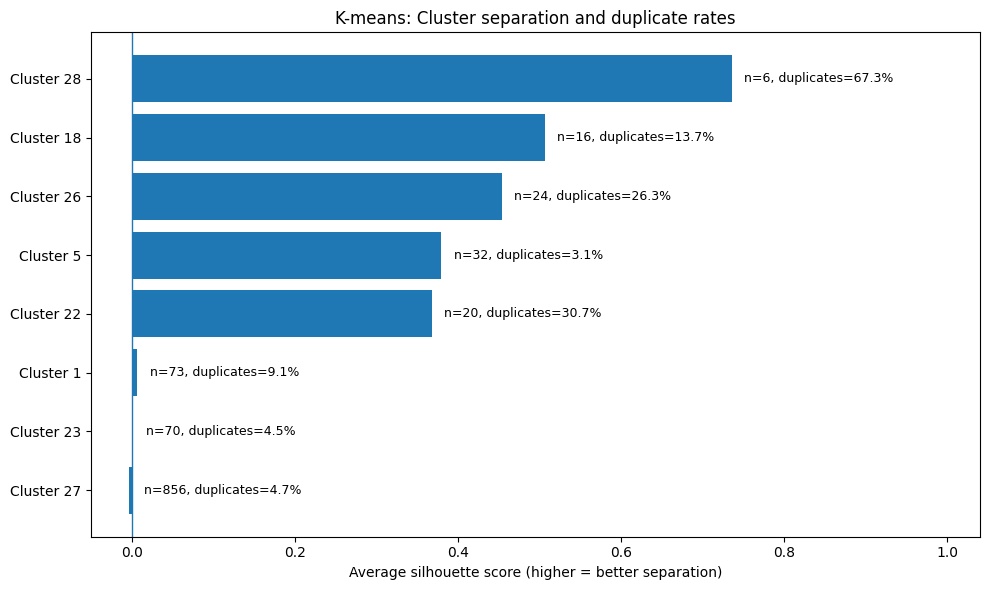

In [10]:

# Step 10: Visualize K-means cluster quality and duplication

import matplotlib.pyplot as plt
import pandas as pd

# Combine silhouette results with duplicate statistics
plot_df = cluster_quality_df.merge(
    duplicate_df[["Cluster", "Duplicate Rate (%)"]],
    on="Cluster",
    how="inner"
)

# Sort by silhouette score
plot_df = plot_df.sort_values("Average Silhouette")

fig, ax = plt.subplots(figsize=(10, 6))

labels = [
    f"Cluster {int(row['Cluster'])}"
    for _, row in plot_df.iterrows()
]

bars = ax.barh(
    labels,
    plot_df["Average Silhouette"]
)

# Add sample sizes and duplication rates
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    score = row["Average Silhouette"]

    ax.annotate(
        f"n={int(row['Sampled Prompts'])}, "
        f"duplicates={row['Duplicate Rate (%)']:.1f}%",
        xy=(max(score, 0) + 0.015,
            bar.get_y() + bar.get_height() / 2),
        va="center",
        fontsize=9
    )

ax.axvline(0, linewidth=1)
ax.set_xlim(-0.05, 1.04)
ax.set_xlabel("Average silhouette score (higher = better separation)")
ax.set_title(
    "K-means: Cluster separation and duplicate rates"
)

plt.tight_layout()

plt.savefig(
    "milestone3_cluster_quality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


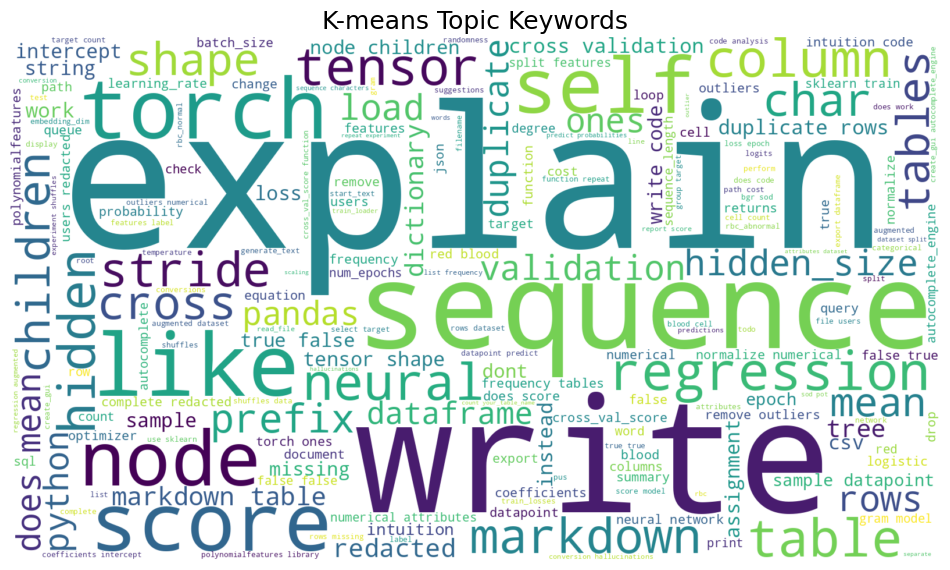

In [11]:
# If needed:
!pip install wordcloud

from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import Counter

# Use your K-means summary table
# This should be the table with columns like:
# Cluster | Prompts | Share (%) | Top Keywords
# Replace cluster_summary_df with your actual dataframe name if needed

word_weights = Counter()

for _, row in cluster_summary_df.iterrows():
    cluster_weight = row["Share (%)"]   # weight by cluster size
    keywords = [w.strip() for w in row["Top Keywords"].split(",")]

    # give more weight to earlier keywords in each cluster
    for rank, word in enumerate(keywords[:8], start=1):
        word_weights[word] += cluster_weight * (9 - rank)

# optional: remove stopwords
remove_words = {
    "make", "use", "using", "does", "just", "want",
    "data", "model", "dataset", "code"
}
for w in remove_words:
    word_weights.pop(w, None)

# create word cloud
wc = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    collocations=False
).generate_from_frequencies(word_weights)

# show it
plt.figure(figsize=(12, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("K-means Topic Keywords", fontsize=18)
plt.show()

Total word occurrences: 611593
Unique words: 12993

20 most frequently used words:
false: 10,707
true: 10,355
self: 9,330
model: 7,286
node: 6,680
sequence: 5,698
char: 5,697
print: 5,669
torch: 4,493
prefix: 4,158
tables: 4,104
def: 4,025
loss: 3,990
return: 3,988
todo: 3,884
dataset: 3,624
data: 3,622
epoch: 3,410
tensor: 3,397
character: 3,329


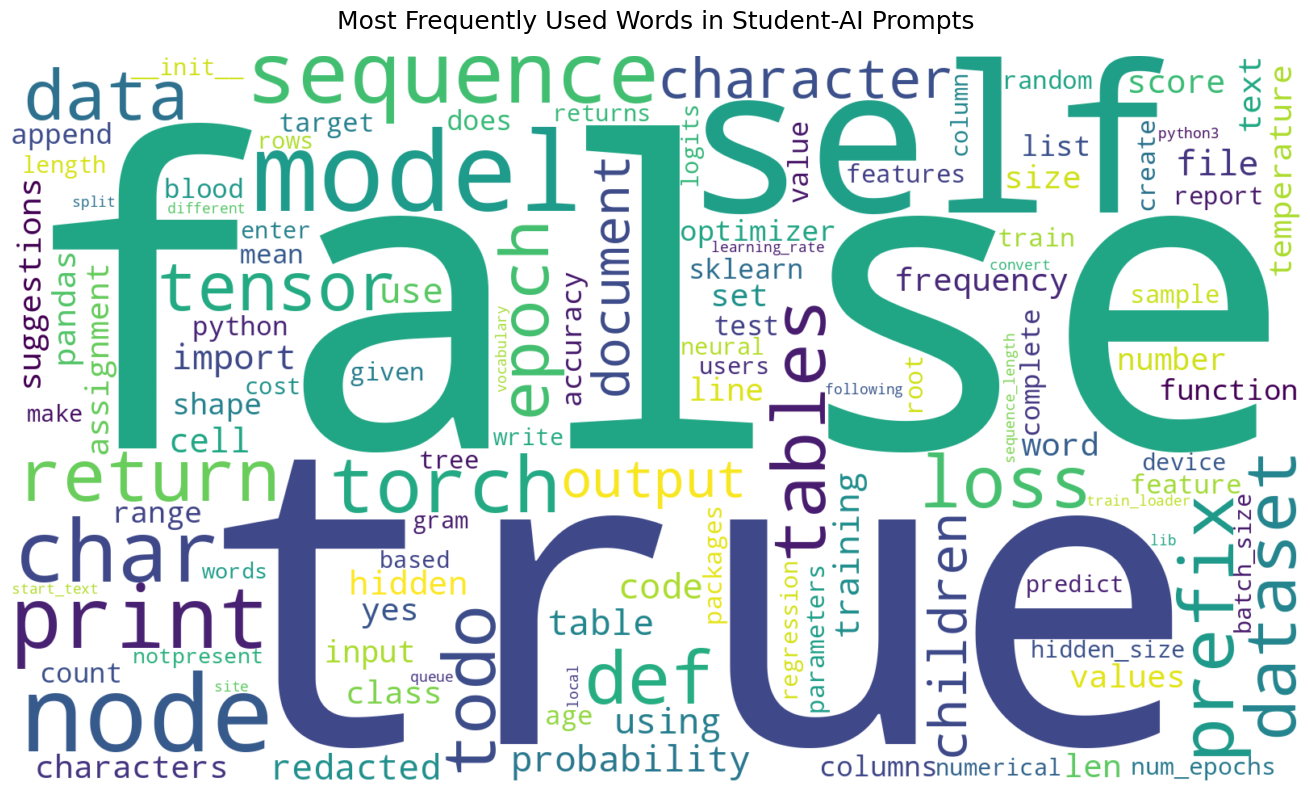


Saved: studychat_word_frequency_cloud.png


In [12]:

# Step 11: Word cloud based on actual student word frequencies

from wordcloud import WordCloud
from collections import Counter
import matplotlib.pyplot as plt

# Count every occurrence of every preprocessed word
all_tokens = []

for text in modeling_corpus["processed_text_v2"].fillna(""):
    all_tokens.extend(text.split())

word_frequencies = Counter(all_tokens)

print("Total word occurrences:", sum(word_frequencies.values()))
print("Unique words:", len(word_frequencies))

print("\n20 most frequently used words:")
for word, count in word_frequencies.most_common(20):
    print(f"{word}: {count:,}")

# Generate a word cloud using actual word frequencies
wordcloud = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    colormap="viridis",
    max_words=120,
    collocations=False,
    random_state=42
).generate_from_frequencies(word_frequencies)

plt.figure(figsize=(14, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title(
    "Most Frequently Used Words in Student-AI Prompts",
    fontsize=18,
    pad=20
)
plt.tight_layout()
plt.savefig(
    "studychat_word_frequency_cloud.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved: studychat_word_frequency_cloud.png")


In [13]:

# Step 12: Create a deduplicated copy of StudyChat

import pandas as pd

# Keep original modeling dataset unchanged
dedup_corpus = modeling_corpus.copy()

# Normalize prompts for duplicate detection
dedup_corpus["normalized_prompt"] = (
    dedup_corpus["prompt"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Remove duplicate prompts, keeping the first occurrence
dedup_corpus = (
    dedup_corpus
    .drop_duplicates(subset="normalized_prompt")
    .reset_index(drop=True)
)

print("Original prompts:", len(modeling_corpus))
print("Unique prompts:", len(dedup_corpus))
print(
    "Duplicates removed:",
    len(modeling_corpus) - len(dedup_corpus)
)
print(
    "Percentage removed:",
    round(
        100 * (1 - len(dedup_corpus) / len(modeling_corpus)),
        2
    ),
    "%"
)

print(
    "Students still represented:",
    dedup_corpus["userId"].nunique()
)


Original prompts: 16597
Unique prompts: 15200
Duplicates removed: 1397
Percentage removed: 8.42 %
Students still represented: 203


In [14]:

# Step 13: Train K-means on deduplicated prompts

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# Reuse the TF-IDF representation from the original experiment
X_dedup = tfidf_vect.transform(
    dedup_corpus["processed_text_v2"].fillna("")
)

# Train with the same K-means settings
kmeans_dedup = KMeans(
    n_clusters=31,
    random_state=42,
    n_init=10
)

labels_dedup = kmeans_dedup.fit_predict(X_dedup)

# Record new cluster assignments
dedup_corpus["cluster_dedup"] = labels_dedup

# Compare cluster-size distributions
original_counts = pd.Series(labels_31).value_counts()
dedup_counts = pd.Series(labels_dedup).value_counts()

print("Original prompts:", X_tfidf.shape[0])
print("Deduplicated prompts:", X_dedup.shape[0])

print("\nORIGINAL K-MEANS")
print("Number of clusters:", len(original_counts))
print("Largest cluster size:", original_counts.max())
print(
    "Largest cluster share:",
    f"{100 * original_counts.max() / len(labels_31):.2f}%"
)

print("\nDEDUPLICATED K-MEANS")
print("Number of clusters:", len(dedup_counts))
print("Largest cluster size:", dedup_counts.max())
print(
    "Largest cluster share:",
    f"{100 * dedup_counts.max() / len(labels_dedup):.2f}%"
)

print("\nFive largest deduplicated clusters:")
display(
    dedup_counts.head(5).to_frame("Prompts")
)


Original prompts: 16597
Deduplicated prompts: 15200

ORIGINAL K-MEANS
Number of clusters: 31
Largest cluster size: 7046
Largest cluster share: 42.45%

DEDUPLICATED K-MEANS
Number of clusters: 31
Largest cluster size: 6550
Largest cluster share: 43.09%

Five largest deduplicated clusters:


,Prompts
8,6550
0,682
10,562
12,479
23,461


In [15]:

# Step 14: Compare K-means models on identical unique prompts

import numpy as np
import pandas as pd

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Select the same 2,000 unique prompts for both models
rng = np.random.default_rng(42)

eval_indices = rng.choice(
    X_dedup.shape[0],
    size=2000,
    replace=False
)

X_eval = X_dedup[eval_indices]

# Predict clusters using both models
original_eval_labels = kmeans_31.predict(X_eval)
dedup_eval_labels = kmeans_dedup.predict(X_eval)

# Silhouette scores on identical prompts
original_silhouette = silhouette_score(
    X_eval,
    original_eval_labels,
    metric="euclidean"
)

dedup_silhouette = silhouette_score(
    X_eval,
    dedup_eval_labels,
    metric="euclidean"
)

# Compare whether prompts are grouped similarly
ari = adjusted_rand_score(
    original_eval_labels,
    dedup_eval_labels
)

nmi = normalized_mutual_info_score(
    original_eval_labels,
    dedup_eval_labels
)

comparison_df = pd.DataFrame([
    {
        "Model": "Original (with duplicates)",
        "Evaluation Prompts": len(eval_indices),
        "Silhouette": original_silhouette
    },
    {
        "Model": "Deduplicated",
        "Evaluation Prompts": len(eval_indices),
        "Silhouette": dedup_silhouette
    }
])

display(comparison_df.round(4))

print(f"Silhouette difference (dedup - original): {dedup_silhouette - original_silhouette:+.4f}")
print(f"Adjusted Rand Index: {ari:.4f}")
print(f"Normalized Mutual Information: {nmi:.4f}")


,Model,Evaluation Prompts,Silhouette
0,Original (with duplicates),2000,0.0520
1,Deduplicated,2000,0.0529


Silhouette difference (dedup - original): +0.0009
Adjusted Rand Index: 0.6002
Normalized Mutual Information: 0.6943


In [16]:

# Step 15: Match original clusters to deduplicated clusters

import pandas as pd
import numpy as np

# Predict original-model labels for unique prompts
original_unique_labels = kmeans_31.predict(X_dedup)
dedup_unique_labels = kmeans_dedup.predict(X_dedup)

# Compare assignments
comparison_table = pd.crosstab(
    pd.Series(original_unique_labels, name="Original Cluster"),
    pd.Series(dedup_unique_labels, name="Deduplicated Cluster")
)

selected_clusters = [28, 26, 5, 27]

results = []

for original_cluster in selected_clusters:
    matches = comparison_table.loc[original_cluster]

    matched_cluster = int(matches.idxmax())
    matched_docs = int(matches.max())
    total_docs = int(matches.sum())

    results.append({
        "Original Cluster": original_cluster,
        "Matched Dedup Cluster": matched_cluster,
        "Original Unique Prompts": total_docs,
        "Prompts in Matched Cluster": matched_docs,
        "Match Rate (%)": (
            100 * matched_docs / total_docs
        )
    })

cluster_match_df = pd.DataFrame(results)

display(cluster_match_df.round(2))


,Original Cluster,Matched Dedup Cluster,Original Unique Prompts,Prompts in Matched Cluster,Match Rate (%)
0,28,8,16,16,100.0
1,26,7,168,167,99.4
2,5,3,217,217,100.0
3,27,8,6717,5488,81.7


In [17]:

# Step 16: Check whether original topics survived deduplication

import pandas as pd

results = []

for original_cluster in [28, 26, 5, 27]:

    matches = comparison_table.loc[original_cluster]

    new_cluster = int(matches.idxmax())
    overlap = int(matches.max())

    original_size = int(matches.sum())
    new_size = int(comparison_table[new_cluster].sum())

    retention = 100 * overlap / original_size
    purity = 100 * overlap / new_size

    # Examine new cluster keywords
    center = kmeans_dedup.cluster_centers_[new_cluster]
    top_indices = center.argsort()[-8:][::-1]

    keywords = ", ".join(
        tfidf_vect.get_feature_names_out()[top_indices]
    )

    results.append({
        "Original Cluster": original_cluster,
        "Dedup Cluster": new_cluster,
        "Original Unique Prompts": original_size,
        "Dedup Cluster Size": new_size,
        "Retention (%)": retention,
        "Match Purity (%)": purity,
        "Dedup Keywords": keywords
    })

survival_df = pd.DataFrame(results)

display(survival_df.round(2))


,Original Cluster,Dedup Cluster,Original Unique Prompts,Dedup Cluster Size,Retention (%),Match Purity (%),Dedup Keywords
0,28,8,16,6550,100.0,0.24,"data, make, model, using, explain, write, just, error"
1,26,7,168,167,99.4,100.00,"query, target, count, sql, select target, group target, target count, group"
2,5,3,217,218,100.0,99.54,"blood, cell, red blood, red, pus, blood cell, cell count, pus cell"
3,27,8,6717,6550,81.7,83.79,"data, make, model, using, explain, write, just, error"


## Effect of Duplicate Prompts on K-means Clustering

To investigate whether repeated student prompts influenced K-means clustering, I removed 1,397 duplicate prompts (8.42%) and retrained the model using the same number of clusters and TF-IDF representation.

Removing duplicates produced only a small improvement in the overall silhouette score, from 0.0520 to 0.0529. However, the topics did not respond equally to deduplication.

A highly repetitive topic about LLM data conversions, which originally contained 67.35% duplicate prompts, lost its separate cluster and became part of a much larger, general-purpose cluster. In contrast, topics involving SQL queries and blood-cell data remained almost entirely intact.

The results suggest that repeated assignment questions may influence whether certain specialized topics emerge as separate clusters, even when overall clustering quality changes very little. However, further experiments across multiple random seeds would be needed to confirm how consistently this occurs.

This highlights an important distinction in the StudyChat dataset: some recurring topics appear to reflect robust patterns across different student questions, while others may be strongly influenced by repeated assignment wording.